[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/processamento-linguagem-natural/notebooks/unidade-03/classificacao-com-cnn-alternativo.ipynb)

> **Revisão documental — 20/10/2026:** Saídas históricas preservadas. C25/C36/C41: os rótulos “Teste” salvos precedem a identificação atual do conjunto como validação. Execução integral desta revisão no Colab pendente.

## Preparação da sessão e dos insumos

Execute a célula abaixo antes das atividades. Ela encontra o repositório na sessão local; no Colab, cria uma cópia em `/content/pos-graduacao-ia-ciencia-dados` apenas se essa pasta ainda não existir, sem alterar o diretório de trabalho. Um clone existente precisa ser atualizado por você quando necessário. Mudanças locais só ficam disponíveis nessa cópia do Colab após serem publicadas no remoto.

O arquivo `glove.6B.50d.txt` não acompanha o checkout. Baixe e extraia o conjunto oficial, seguindo [as instruções do GloVe](../../dados/glove/README.md), e copie ou envie o arquivo para `disciplinas/processamento-linguagem-natural/dados/glove/` dentro do repositório da sessão. A célula informa o destino absoluto se o arquivo estiver ausente; após o envio, execute-a novamente.

As saídas salvas e os nomes dos exemplos foram preservados como registros históricos. A preparação dos caminhos não valida a execução integral nem a compatibilidade das demais dependências.

## Alcance da avaliação

Este exemplo usa uma divisão didática em treino e validação. Os nomes `X_test`, `y_test`, `tk_pad_X_test` e `ohe_y_test` foram mantidos no código, mas identificam o conjunto usado em `validation_data` para monitoramento a cada época. Cada chamada posterior a `evaluate` reutiliza esses mesmos dados; sua acurácia descreve o conjunto usado para validação. Não há uma reserva de teste independente para avaliar escolhas baseadas nesse monitoramento ou na comparação das variantes.

As saídas salvas são históricas: rótulos antigos como “Acurácia do Teste” não demonstram avaliação independente e não representam uma nova execução das fontes corrigidas.

In [ ]:
from pathlib import Path
import subprocess

SLUG = "processamento-linguagem-natural"
_session_dir = Path.cwd().resolve()
REPO_DIR = next(
    (p for p in (_session_dir, *_session_dir.parents)
     if (p / "disciplinas" / SLUG).is_dir()),
    None,
)
if REPO_DIR is None:
    if not Path("/content").is_dir():
        raise FileNotFoundError("Abra a sessão na raiz do repositório ou em uma de suas subpastas.")
    REPO_DIR = Path("/content/pos-graduacao-ia-ciencia-dados")
    if not REPO_DIR.exists():
        subprocess.run([
            "git", "clone", "--depth", "1",
            "https://github.com/wellingtonmnf/pos-graduacao-ia-ciencia-dados.git",
            str(REPO_DIR),
        ], check=True)

DISCIPLINA_DIR = REPO_DIR / "disciplinas" / SLUG
DATA_DIR = DISCIPLINA_DIR / "dados"
if not DISCIPLINA_DIR.is_dir() or not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Estrutura de dados ausente em {DISCIPLINA_DIR}. Atualize o clone para a revisão que contém dados/."
    )

GLOVE_PATH = DATA_DIR / "glove" / "glove.6B.50d.txt"
if not GLOVE_PATH.is_file():
    raise FileNotFoundError(
        f"Obtenha manualmente glove.6B.50d.txt e copie para {GLOVE_PATH}. "
        f"Consulte {DATA_DIR / 'glove' / 'README.md'}. Depois, execute esta célula novamente."
    )

In [ ]:
%matplotlib inline
# Mesmo CSV IMDb das demais práticas, na versão comparada em 2026-10-19.
%pip install "kagglehub[pandas-datasets]"
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "IMDB Dataset.csv"
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1",
    file_path,
)

if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("Colunas inesperadas no IMDb")
if df["review"].isna().any() or not df["review"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
    raise ValueError("Resenhas ausentes ou inválidas")
if df["sentiment"].isna().any() or not df["sentiment"].isin(["positive", "negative"]).all():
    raise ValueError("Rótulos inesperados no IMDb")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [ ]:
df['sentiment'].value_counts()

negative    25000
positive    25000
Name: sentiment, dtype: int64

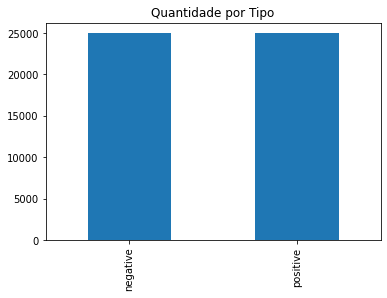

In [ ]:
df["sentiment"].value_counts().plot.bar(title='Quantidade por Tipo',rot=90)

In [ ]:
!pip install nltk
import nltk
nltk.download('stopwords')
nltk.download("punkt_tab", raise_on_error=True)
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Unzipping corpora/wordnet.zip.


True

In [ ]:
exemplo = df['review'].values[0]
print(exemplo)
print(len(exemplo.split()))

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [ ]:
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    return palavras
exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['One', 'reviewers', 'mentioned', 'watching', '1', 'Oz', 'episode', "'ll", 'hooked', 'They', 'right', 'exactly', 'happened', 'me.', 'br', 'br', 'The', 'first', 'thing', 'struck', 'Oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set', 'right', 'word', 'GO', 'Trust', 'show', 'faint', 'hearted', 'timid', 'This', 'show', 'pulls', 'punches', 'regards', 'drugs', 'sex', 'violence', 'Its', 'hardcore', 'classic', 'use', 'word.', 'br', 'br', 'It', 'called', 'OZ', 'nickname', 'given', 'Oswald', 'Maximum', 'Security', 'State', 'Penitentary', 'It', 'focuses', 'mainly', 'Emerald', 'City', 'experimental', 'section', 'prison', 'cells', 'glass', 'fronts', 'face', 'inwards', 'privacy', 'high', 'agenda', 'Em', 'City', 'home', 'many..Aryans', 'Muslims', 'gangstas', 'Latinos', 'Christians', 'Italians', 'Irish', '...', '.so', 'scuffles', 'death', 'stares', 'dodgy', 'dealings', 'shady', 'agreements', 'never', 'far', 'away.', 'br', 'br', 'I', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 'g

In [ ]:
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
TAMANHO_MIMINO = 1
IGNORAR = ['...', 'br','.so','\'ll']
from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer('english')
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    palavras = [i for i in palavras if len(i) > TAMANHO_MIMINO]
    palavras = [i.lower() for i in palavras if i not in IGNORAR]
    palavras = [stemmer.stem(i) for i in palavras]
    return palavras
exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['one', 'review', 'mention', 'watch', 'oz', 'episod', 'hook', 'they', 'right', 'exact', 'happen', 'me.', 'the', 'first', 'thing', 'struck', 'oz', 'brutal', 'unflinch', 'scene', 'violenc', 'set', 'right', 'word', 'go', 'trust', 'show', 'faint', 'heart', 'timid', 'this', 'show', 'pull', 'punch', 'regard', 'drug', 'sex', 'violenc', 'it', 'hardcor', 'classic', 'use', 'word.', 'it', 'call', 'oz', 'nicknam', 'given', 'oswald', 'maximum', 'secur', 'state', 'penitentari', 'it', 'focus', 'main', 'emerald', 'citi', 'experiment', 'section', 'prison', 'cell', 'glass', 'front', 'face', 'inward', 'privaci', 'high', 'agenda', 'em', 'citi', 'home', 'many..aryan', 'muslim', 'gangsta', 'latino', 'christian', 'italian', 'irish', 'scuffl', 'death', 'stare', 'dodgi', 'deal', 'shadi', 'agreement', 'never', 'far', 'away.', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 'goe', 'show', 'would', "n't", 'dare', 'forget', 'pretti', 'pictur', 'paint', 'mainstream', 'audienc', 'forget', 'charm', 'forget',

In [ ]:
%%time
df['review2'] = df['review'].apply(prepara)
df['review2'] = df['review2'].apply(' '.join)

CPU times: user 3min 4s, sys: 640 ms, total: 3min 4s
Wall time: 3min 4s


In [ ]:
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one review mention watch oz episod hook they r...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product the film techniqu unassum...
2,I thought this was a wonderful way to spend ti...,positive,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,negative,basic 's famili littl boy jake think 's zombi ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visual ...


In [ ]:
df.to_pickle('nano')

In [ ]:
import pandas as pd
df = pd.read_pickle('nano')
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one review mention watch oz episod hook they r...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product the film techniqu unassum...
2,I thought this was a wonderful way to spend ti...,positive,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,negative,basic 's famili littl boy jake think 's zombi ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visual ...


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['review2'], df['sentiment'], test_size=0.2, random_state=0)
print('X_train shape:',X_train.shape)
print('y_train shape:',y_train.shape)
print('X_test shape:',X_test.shape)
print('y_test shape:',y_test.shape)

X_train shape: (40000,)
y_train shape: (40000,)
X_test shape: (10000,)
y_test shape: (10000,)


In [ ]:
%%time
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(X_train)
tk_X_train = tokenizer.texts_to_sequences(X_train)
tk_X_test = tokenizer.texts_to_sequences(X_test)
vocab_size = len(tokenizer.word_index) + 1
# A Series preserva rótulos após a divisão; iloc seleciona a posição da sequência tokenizada.
# A impressão salva abaixo é histórica e não foi recalculada.
print(X_train.iloc[0])
print(tk_X_train[0])

one review mention watch oz episod hook they right exact happen me. the first thing struck oz brutal unflinch scene violenc set right word go trust show faint heart timid this show pull punch regard drug sex violenc it hardcor classic use word. it call oz nicknam given oswald maximum secur state penitentari it focus main emerald citi experiment section prison cell glass front face inward privaci high agenda em citi home many..aryan muslim gangsta latino christian italian irish scuffl death stare dodgi deal shadi agreement never far away. would say main appeal show due fact goe show would n't dare forget pretti pictur paint mainstream audienc forget charm forget romanc oz n't mess around the first episod ever saw struck nasti surreal could n't say readi watch develop tast oz got accustom high level graphic violenc not violenc injustic crook guard sold nickel inmat kill order get away well manner middl class inmat turn prison bitch due lack street skill prison experi watch oz may becom c

In [ ]:
for word in ['film','the','one']:
     print('{}: {}'.format(word, tokenizer.word_index[word]))

film: 3
the: 4
one: 7


In [ ]:
print('Max size:',max([len(i) for i in tk_X_train]))

Max size: 1374


In [ ]:
from keras.utils import pad_sequences
max_len = max([len(i) for i in tk_X_train])
tk_pad_X_train = pad_sequences(tk_X_train, padding='post', maxlen=max_len)
tk_pad_X_test = pad_sequences(tk_X_test, padding='post', maxlen=max_len)
print(tk_pad_X_train[0, :])

[ 136    1 1230 ...    0    0    0]


In [ ]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
ohe_y_train = lb.fit_transform(y_train)
ohe_y_test = lb.transform(y_test)
print('ohe_y_train shape:',ohe_y_train.shape)
print('ohe_y_test shape:',ohe_y_test.shape)

ohe_y_train shape: (40000, 1)
ohe_y_test shape: (10000, 1)


In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, GlobalMaxPool1D, Dropout, Conv1D, GlobalMaxPooling1D, MaxPooling1D
from keras.optimizers import Adam

In [ ]:
NB_EPOCH = 10
BATCH_SIZE = 128
VERBOSE = 1
OPTIMIZER = Adam()

In [ ]:
from keras import Input

model = Sequential()
model.add(Input(shape=(max_len,), dtype="int32"))
model.add(Embedding(input_dim=vocab_size, output_dim=50))
model.add(GlobalMaxPool1D())
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (None, 1374, 50)          3695700   
_________________________________________________________________
global_max_pooling1d (Global (None, 50)                0         
_________________________________________________________________
dense (Dense)                (None, 16)                816       
_________________________________________________________________
dropout (Dropout)            (None, 16)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 1)                 17        
Total params: 3,696,533
Trainable params: 3,696,533
Non-trainable params: 0
_________________________________________________________________


In [ ]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/10
313/313 [==============================] - 21s 56ms/step - loss: 0.6328 - accuracy: 0.6636 - val_loss: 0.3654 - val_accuracy: 0.8453
Epoch 2/10
313/313 [==============================] - 17s 54ms/step - loss: 0.3548 - accuracy: 0.8576 - val_loss: 0.3109 - val_accuracy: 0.8696
Epoch 3/10
313/313 [==============================] - 17s 53ms/step - loss: 0.2856 - accuracy: 0.8917 - val_loss: 0.2940 - val_accuracy: 0.8766
Epoch 4/10
313/313 [==============================] - 17s 53ms/step - loss: 0.2220 - accuracy: 0.9220 - val_loss: 0.2879 - val_accuracy: 0.8801
Epoch 5/10
313/313 [==============================] - 16s 52ms/step - loss: 0.1858 - accuracy: 0.9404 - val_loss: 0.2958 - val_accuracy: 0.8808
Epoch 6/10
313/313 [==============================] - 16s 53ms/step - loss: 0.1479 - accuracy: 0.9558 - val_loss: 0.3108 - val_accuracy: 0.8767
Epoch 7/10
313/313 [==============================] - 17s 53ms/step - loss: 0.1193 - accuracy: 0.9666 - val_loss: 0.3301 - val_accuracy:

In [ ]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.8762


In [ ]:
import matplotlib.pyplot as plt
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training accuracy')
    plt.plot(x, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()


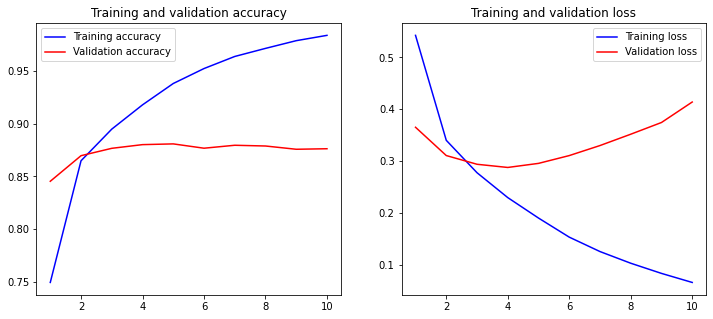

In [ ]:
plot_history(history)

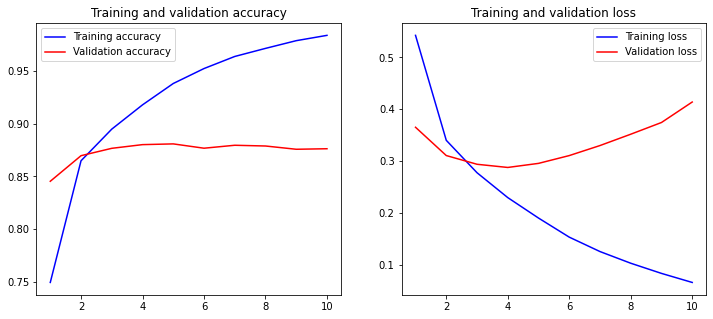

In [ ]:
plot_history(history)

In [ ]:
# O diretório do processo é preservado; utilize GLOVE_PATH definido na preparação.

/content/drive/MyDrive/Colab Notebooks


In [ ]:
%ls -la

total 320185
-rw------- 1 root root   2243257 Sep 10  2020 '7. examples.ipynb'
-rw------- 1 root root    105690 Sep  4  2020  aima_agents.ipynb
-rw------- 1 root root     82749 Oct 26 22:49  aima_logic.ipynb
drwx------ 2 root root      4096 Aug 31  2020  aima-python/
-rw------- 1 root root   1833759 Oct 14  2020  aima_search.ipynb
-rw------- 1 root root     16979 Apr 11 23:30 'Bonus - Reconhecimento de Entidades Nomeadas.ipynb'
-rw------- 1 root root  11782370 Nov 10 04:04  CopiaVC_1_Lab_09_MNIST_CNN_DataAug.ipynb
-rw------- 1 root root     20598 Jun 20  2020 'Copy of regression.ipynb'
-rw------- 1 root root     28475 Apr 23 23:01 'Curso PLN - Tópico 1.ipynb'
-rw------- 1 root root  23872904 Apr 24 00:11 'Curso PLN - Tópico 2 - DNN.ipynb'
-rw------- 1 root root     57752 Apr 23 23:52 'Curso PLN - Tópico 2.ipynb'
-rw------- 1 root root     58115 Apr 24 00:02 'Curso PLN - Tópico 2 - TF-IDF.ipynb'
-rw------- 1 root root     45808 Apr 26 20:53 'Curso PLN - Tópico 3 - CNN.ipynb'
-rw---

In [ ]:
with GLOVE_PATH.open("r", encoding="utf-8") as f:
    print(f.readline(100).rstrip())

the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.044457 -0.49688 -0.17862 -0.00066023 -0.6566 0.27843 -0


In [ ]:
import numpy as np
def create_embedding(path, word_index, embedding_dim):
    vocab_size = len(word_index) + 1
    embedding = np.zeros((vocab_size, embedding_dim))
    with open(path) as f:
        for line in f:
            w, *vector = line.split()
            if w in word_index:
                idx = word_index[w]
                embedding[idx] = np.array(vector, dtype=np.float32)[:embedding_dim]
    return embedding

In [ ]:
%%time
embedding_dim = 50
embedding_matrix = create_embedding(GLOVE_PATH, tokenizer.word_index, embedding_dim)
print(embedding_matrix.shape)

(73914, 50)
CPU times: user 2.17 s, sys: 122 ms, total: 2.29 s
Wall time: 3.42 s


In [ ]:
from keras import Input

model = Sequential()
model.add(Input(shape=(max_len,), dtype="int32"))
model.add(Embedding(input_dim=vocab_size, output_dim=50, weights=[embedding_matrix]))
model.add(GlobalMaxPool1D())
model.add(Dense(24, activation='relu'))
model.add(Dense(1, activation='sigmoid'))
OPTIMIZER = Adam()
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_1 (Embedding)      (None, 1374, 50)          3695700   
_________________________________________________________________
global_max_pooling1d_1 (Glob (None, 50)                0         
_________________________________________________________________
dense_2 (Dense)              (None, 24)                1224      
_________________________________________________________________
dense_3 (Dense)              (None, 1)                 25        
Total params: 3,696,949
Trainable params: 3,696,949
Non-trainable params: 0
_________________________________________________________________


In [ ]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/10
313/313 [==============================] - 17s 53ms/step - loss: 0.6205 - accuracy: 0.6506 - val_loss: 0.4399 - val_accuracy: 0.7980
Epoch 2/10
313/313 [==============================] - 16s 52ms/step - loss: 0.3951 - accuracy: 0.8237 - val_loss: 0.3889 - val_accuracy: 0.8299
Epoch 3/10
313/313 [==============================] - 16s 52ms/step - loss: 0.3384 - accuracy: 0.8562 - val_loss: 0.3723 - val_accuracy: 0.8376
Epoch 4/10
313/313 [==============================] - 17s 53ms/step - loss: 0.3037 - accuracy: 0.8718 - val_loss: 0.3667 - val_accuracy: 0.8403
Epoch 5/10
313/313 [==============================] - 16s 53ms/step - loss: 0.2840 - accuracy: 0.8839 - val_loss: 0.3645 - val_accuracy: 0.8416
Epoch 6/10
313/313 [==============================] - 16s 52ms/step - loss: 0.2665 - accuracy: 0.8922 - val_loss: 0.3654 - val_accuracy: 0.8439
Epoch 7/10
313/313 [==============================] - 16s 52ms/step - loss: 0.2484 - accuracy: 0.9012 - val_loss: 0.3650 - val_accuracy:

In [ ]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.8433


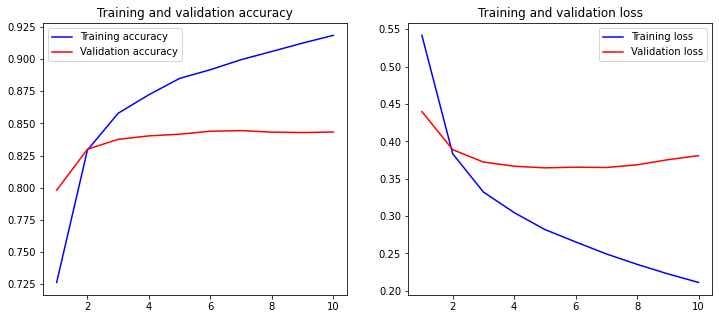

In [ ]:
plot_history(history)

In [ ]:
NB_EPOCH = 3
BATCH_SIZE = 128
VERBOSE = 1
OPTIMIZER = Adam()
print(vocab_size)

73914


In [ ]:
from keras import Input

model = Sequential()
model.add(Input(shape=(max_len,), dtype="int32"))
model.add(Embedding(vocab_size, 128))
model.add(Conv1D(64, 5, activation='relu'))
model.add(MaxPooling1D())
model.add(Flatten())
model.add(Dropout(rate=0.4))
model.add(Dense(32, activation='relu'))
model.add(Dropout(rate=0.4))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_2 (Embedding)      (None, 1374, 128)         9460992   
_________________________________________________________________
conv1d (Conv1D)              (None, 1370, 64)          41024     
_________________________________________________________________
max_pooling1d (MaxPooling1D) (None, 685, 64)           0         
_________________________________________________________________
flatten (Flatten)            (None, 43840)             0         
_________________________________________________________________
dropout_1 (Dropout)          (None, 43840)             0         
_________________________________________________________________
dense_4 (Dense)              (None, 32)                1402912   
_________________________________________________________________
dropout_2 (Dropout)          (None, 32)               

In [ ]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/3
313/313 [==============================] - 77s 150ms/step - loss: 0.5376 - accuracy: 0.6759 - val_loss: 0.2665 - val_accuracy: 0.8921
Epoch 2/3
313/313 [==============================] - 47s 149ms/step - loss: 0.2123 - accuracy: 0.9243 - val_loss: 0.2623 - val_accuracy: 0.8931
Epoch 3/3
313/313 [==============================] - 47s 149ms/step - loss: 0.1539 - accuracy: 0.9464 - val_loss: 0.3046 - val_accuracy: 0.8866
CPU times: user 3min 5s, sys: 6.28 s, total: 3min 11s
Wall time: 2min 50s


In [ ]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.8866


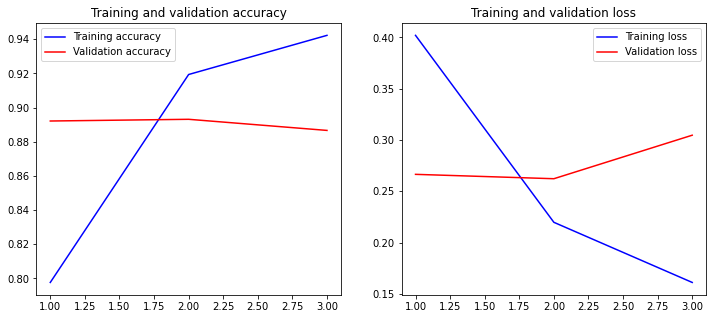

In [ ]:
plot_history(history)

FIM